In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
from pathlib import Path
import seaborn as sns 
import matplotlib as mpl
from scipy.stats import linregress
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

In [ ]:
# Directory navigation:
folder_str = r"C:\\...\\00_processed"
parent_folder = Path(r"C:\...\00_processed")
filelst = list(parent_folder.glob("*.csv"))
filenames = [f.name for f in filelst]
filenames

['05pcent_HA_C001H001S0001_20260128_155943.csv',
 '05pcent_HA_C001H001S0001_20260128_161525.csv',
 '05pcent_HA_C001H001S0001_20260128_163204.csv',
 '1pcent_HA_C001H001S0001_20260128_145920.csv',
 '1pcent_HA_C001H001S0001_20260128_151800.csv',
 '1pcent_HA_C001H001S0001_20260128_154058.csv',
 '2pcent_HA_C001H001S0001_20260128_125306.csv',
 '2pcent_HA_C001H001S0001_20260128_131040.csv',
 '2pcent_HA_C001H001S0001_20260128_132731.csv',
 'E40000_C001H001S0001_20260303_154744.csv',
 'E40000_C001H001S0001_20260304_115714.csv',
 'E40000_C001H001S0001_20260304_125631.csv',
 'E6000_testfluid_C001H001S0001_20260129_174059.csv',
 'E6000_testfluid_C001H001S0001_20260129_175058.csv',
 'E6000_testfluid_C001H001S0001_20260129_181025.csv',
 'Glycerol_C001H001S0001_20260310_153121.csv',
 'Glycerol_C001H001S0001_20260310_155758.csv',
 'Glycerol_C001H001S0001_20260310_163822.csv']

DATA PROCESSING AND CLEANUP

In [3]:
# Read each file into a data frame
data_dict = {} # dictionary of data frames, raw
for i in range(len(filelst)):
    data_dict[filenames[i]] = pd.read_csv(filelst[i])

data_dict[filenames[0]]
# print(filenames[3][:3])
# "05_" in filenames[3]


,true frame index,"tstamp, ms",img list frame index,expt_time(ms),"d, pixels",y at break,d/do
0,326.0,326.0,7.0,0.0,25.0,331.0,1.00
1,327.0,327.0,8.0,1.0,23.0,330.0,0.92
2,328.0,328.0,9.0,2.0,23.0,330.0,0.92
3,329.0,329.0,10.0,3.0,21.0,332.0,0.84
4,330.0,330.0,11.0,4.0,20.0,332.0,0.80
5,331.0,331.0,12.0,5.0,20.0,331.0,0.80
6,332.0,332.0,13.0,6.0,18.0,332.0,0.72
7,333.0,333.0,14.0,7.0,17.0,334.0,0.68
8,334.0,334.0,15.0,8.0,16.0,331.0,0.64
9,335.0,335.0,16.0,9.0,15.0,332.0,0.60


In [4]:
# list of unique experimental conditions
expts:list = ["05p", "1p", "2p", "E6000", "E40000", "Glycerol"]
# print(expts)

# dictionary with list of filenames associated with a given experimental condition(the triplicate filenames)
org_expts = {}  # DICTIONARY OF FILENEAMES and EXPERIMENTAL CONDITIONS. Used to access the data frames associated with each experimental condition, 
                # which are stored in data_dict with key = filename.
for expt in expts:
    print(expt)
    n_lst = []
    for f in filenames:   # Finding the triplicate files associated with each experimental condition, then appending to list
        if expt in f:
            n_lst.append(f)
    print(n_lst)
    org_expts.update({expt: n_lst})   # adding to dictionary with key = expt, value = list of associated filenames

data_dict[org_expts[expts[1]][0]]

05p
['05pcent_HA_C001H001S0001_20260128_155943.csv', '05pcent_HA_C001H001S0001_20260128_161525.csv', '05pcent_HA_C001H001S0001_20260128_163204.csv']
1p
['1pcent_HA_C001H001S0001_20260128_145920.csv', '1pcent_HA_C001H001S0001_20260128_151800.csv', '1pcent_HA_C001H001S0001_20260128_154058.csv']
2p
['2pcent_HA_C001H001S0001_20260128_125306.csv', '2pcent_HA_C001H001S0001_20260128_131040.csv', '2pcent_HA_C001H001S0001_20260128_132731.csv']
E6000
['E6000_testfluid_C001H001S0001_20260129_174059.csv', 'E6000_testfluid_C001H001S0001_20260129_175058.csv', 'E6000_testfluid_C001H001S0001_20260129_181025.csv']
E40000
['E40000_C001H001S0001_20260303_154744.csv', 'E40000_C001H001S0001_20260304_115714.csv', 'E40000_C001H001S0001_20260304_125631.csv']
Glycerol
['Glycerol_C001H001S0001_20260310_153121.csv', 'Glycerol_C001H001S0001_20260310_155758.csv', 'Glycerol_C001H001S0001_20260310_163822.csv']


,true frame index,"tstamp, ms",img list frame index,expt_time(ms),"d, pixels",y at break,d/do
0,328.0,328.0,5.0,0.0,51.0,327.0,1.000000
1,329.0,329.0,6.0,1.0,51.0,324.0,1.000000
2,330.0,330.0,7.0,2.0,50.0,327.0,0.980392
3,331.0,331.0,8.0,3.0,50.0,324.0,0.980392
4,332.0,332.0,9.0,4.0,50.0,325.0,0.980392
...,...,...,...,...,...,...,...
171,499.0,499.0,176.0,171.0,2.0,327.0,0.039216
172,500.0,500.0,177.0,172.0,2.0,327.0,0.039216
173,501.0,501.0,178.0,173.0,1.0,339.0,0.019608
174,502.0,502.0,179.0,174.0,1.0,334.0,0.019608


In [5]:
# converting d, pixels into d, mm
conv = 0.043 #mm/pixel obtained from video frame analysis. 
d0 = 6 #mm, this is the initial diameter of the plate and thus the fluid

for f in data_dict.keys():
    data_dict[f]["d_mm"] = data_dict[f]["d, pixels"]*conv  # Converting d,pixels into d, mm
    data_dict[f]["d/d0, mm"] = data_dict[f]["d_mm"]/d0  # computing true d/do
    data_dict[f]["tbreak - t"] = data_dict[f]["expt_time(ms)"].iloc[-1] - data_dict[f]["expt_time(ms)"]# Computing tbreak - t, which is the time delta between breakage and the current time point. 
data_dict[org_expts[expts[1]][2]]

,true frame index,"tstamp, ms",img list frame index,expt_time(ms),"d, pixels",y at break,d/do,d_mm,"d/d0, mm",tbreak - t
0,328.0,328.0,10.0,0.0,49.0,328.0,1.000000,2.107,0.351167,188.0
1,329.0,329.0,11.0,1.0,49.0,328.0,1.000000,2.107,0.351167,187.0
2,330.0,330.0,12.0,2.0,48.0,331.0,0.979592,2.064,0.344000,186.0
3,331.0,331.0,13.0,3.0,48.0,333.0,0.979592,2.064,0.344000,185.0
4,332.0,332.0,14.0,4.0,48.0,328.0,0.979592,2.064,0.344000,184.0
...,...,...,...,...,...,...,...,...,...,...
184,512.0,512.0,194.0,184.0,2.0,324.0,0.040816,0.086,0.014333,4.0
185,513.0,513.0,195.0,185.0,2.0,331.0,0.040816,0.086,0.014333,3.0
186,514.0,514.0,196.0,186.0,2.0,336.0,0.040816,0.086,0.014333,2.0
187,515.0,515.0,197.0,187.0,1.0,325.0,0.020408,0.043,0.007167,1.0


In [6]:
# Averaging the data - new, relevant data, aligned to expt_time(ms).
# Important columns: "expt_time(ms)", "tbreak - t", "d_mm","d/d0, mm"

# Compiling data
averaged = {}
for expt in expts:
    averaged.update({expt: pd.concat([data_dict[org_expts[expt][0]][["expt_time(ms)", "tbreak - t", "d_mm","d/d0, mm"]], 
                                      data_dict[org_expts[expt][1]][["expt_time(ms)", "tbreak - t", "d_mm","d/d0, mm"]],
                                      data_dict[org_expts[expt][2]][["expt_time(ms)", "tbreak - t", "d_mm","d/d0, mm"]]], axis = 1)})
averaged[expts[0]].tail(20)

#averaging
for expt in expts:
    averaged[expt]["avg_expt_time"] = averaged[expt].iloc[:, [0,4,8]].mean(axis = 1)
    averaged[expt]["std_expt_time"] = averaged[expt].iloc[:, [0,4,8]].std(axis = 1)
    averaged[expt]["avg_tc-t"] = averaged[expt].iloc[:, [1,5,9]].mean(axis = 1)
    averaged[expt]["std_tc-t"] = averaged[expt].iloc[:, [1,5,9]].std(axis = 1)
    averaged[expt]["avg_d, mm"] = averaged[expt].iloc[:, [2,6,10]].mean(axis = 1)
    averaged[expt]["std_d, mm"] = averaged[expt].iloc[:, [2,6,10]].std(axis = 1)
    averaged[expt]["avg_d/d0, mm"] = averaged[expt].iloc[:, [3,7,11]].mean(axis = 1)
    averaged[expt]["std_d/d0, mm"] = averaged[expt].iloc[:, [3,7,11]].std(axis = 1)


# averaged[expts[1]].tail(50)


In [7]:
# Averaging the data - new, relevant data.
# Compiling data: tbreak-t, d,mm and d/d0. aligning the data based on tbreak-t instead of expt_time.
# Assembling all into a dictionary with key = expt, value = dataframe with the relevant columns from the triplicates concatenated together.

averaged_tbreak_aligned = {} 
for expt in expts:
    # Sort each data frame by tbreak-t. mask gets rid of any NaN values in d_mm column
    df_1 = data_dict[org_expts[expt][0]].sort_values(by="tbreak - t").reset_index(drop = True)
    mask_1 = df_1["d_mm"].notna()
    df_2 = data_dict[org_expts[expt][1]].sort_values(by="tbreak - t").reset_index(drop = True)
    mask_2 = df_2["d_mm"].notna()
    df_3 = data_dict[org_expts[expt][2]].sort_values(by="tbreak - t").reset_index(drop = True)
    mask_3 = df_3["d_mm"].notna()
    # combining the aligned data frames into a single data frame, and adding to dictionary with key = expt, value = combined data frame
    averaged_tbreak_aligned.update({expt: pd.concat([df_1[["tbreak - t", "d_mm","d/d0, mm"]][mask_1],
                                                      df_2[["tbreak - t", "d_mm","d/d0, mm"]][mask_2],
                                                      df_3[["tbreak - t", "d_mm","d/d0, mm"]][mask_3]], axis = 1)})
    
# averaged_tbreak_aligned[expts[0]].tail(20)

#averaging
for expt in expts:
    averaged_tbreak_aligned[expt]["avg_tc-t"] = averaged_tbreak_aligned[expt].iloc[:, [0,3,6]].mean(axis = 1)
    averaged_tbreak_aligned[expt]["std_tc-t"] = averaged_tbreak_aligned[expt].iloc[:, [0,3,6]].std(axis = 1)
    averaged_tbreak_aligned[expt]["avg_d, mm"] = averaged_tbreak_aligned[expt].iloc[:, [1,4,7]].mean(axis = 1)
    averaged_tbreak_aligned[expt]["std_d, mm"] = averaged_tbreak_aligned[expt].iloc[:, [1,4,7]].std(axis = 1)
    averaged_tbreak_aligned[expt]["avg_d/d0, mm"] = averaged_tbreak_aligned[expt].iloc[:, [2,5,8]].mean(axis = 1)
    averaged_tbreak_aligned[expt]["std_d/d0, mm"] = averaged_tbreak_aligned[expt].iloc[:, [2,5,8]].std(axis = 1)


averaged_tbreak_aligned[expts[1]].head(40)


,tbreak - t,d_mm,"d/d0, mm",tbreak - t,d_mm,"d/d0, mm",tbreak - t,d_mm,"d/d0, mm",avg_tc-t,std_tc-t,"avg_d, mm","std_d, mm","avg_d/d0, mm","std_d/d0, mm"
0,0.0,0.000,0.000000,0.0,0.000,0.000000,0.0,0.000,0.000000,0.0,0.0,0.000000,0.000000e+00,0.000000,0.000000
1,1.0,0.043,0.007167,1.0,0.043,0.007167,1.0,0.043,0.007167,1.0,0.0,0.043000,8.498375e-18,0.007167,0.000000
2,2.0,0.043,0.007167,2.0,0.043,0.007167,2.0,0.086,0.014333,2.0,0.0,0.057333,2.482606e-02,0.009556,0.004138
3,3.0,0.086,0.014333,3.0,0.086,0.014333,3.0,0.086,0.014333,3.0,0.0,0.086000,1.699675e-17,0.014333,0.000000
4,4.0,0.086,0.014333,4.0,0.086,0.014333,4.0,0.086,0.014333,4.0,0.0,0.086000,1.699675e-17,0.014333,0.000000
5,5.0,0.086,0.014333,5.0,0.086,0.014333,5.0,0.129,0.021500,5.0,0.0,0.100333,2.482606e-02,0.016722,0.004138
6,6.0,0.129,0.021500,6.0,0.129,0.021500,6.0,0.129,0.021500,6.0,0.0,0.129000,0.000000e+00,0.021500,0.000000
7,7.0,0.129,0.021500,7.0,0.129,0.021500,7.0,0.129,0.021500,7.0,0.0,0.129000,0.000000e+00,0.021500,0.000000
8,8.0,0.172,0.028667,8.0,0.129,0.021500,8.0,0.172,0.028667,8.0,0.0,0.157667,2.482606e-02,0.026278,0.004138
9,9.0,0.172,0.028667,9.0,0.172,0.028667,9.0,0.172,0.028667,9.0,0.0,0.172000,3.399350e-17,0.028667,0.000000


ANALYSIS AND GRAPHING

In [8]:
# Setting font
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.family'] = 'sans-serif'

# setting line width
plt.rcParams['axes.linewidth'] = 1.5

# Figure colours setup
run_colours = {expts[0]: "red", 
            expts[1]: "blue",
            expts[2]: "green",
            expts[3]: "blue",
            expts[4]: "green",
            expts[5]: "green"}

# Legend names setup
label_names = {expts[0]: "0.5% HA", 
            expts[1]: "1% HA",
            expts[2]: "2% HA",
            expts[3]: "E6000 test fluid",
            expts[4]: "E40000 test fluid",
            expts[5]: "Glycerol"}  

HYALURONIC ACID-----------------------------------------

0.5%HA: r-square = 0.9756360193691126 tao = 2.017718179177127 +/- 0.06543259803975529
1%HA: r-square = 0.9702218822174151 tao = 3.8370347162317024 +/- 0.29797870506462265
2%HA: r-square = 0.9084130083757351 tao = 10.216158113334522 +/- 0.43836047337104334


(-4.0, -0.8)

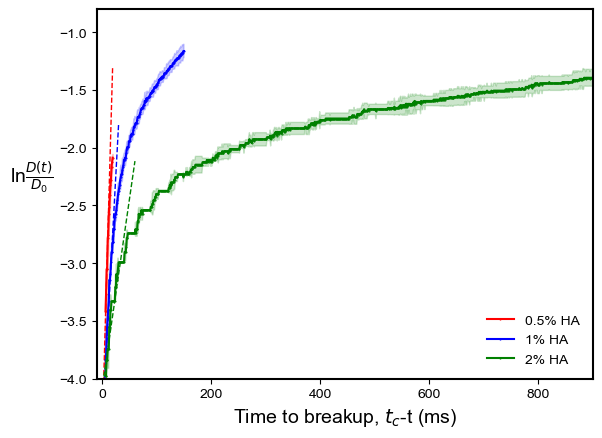

In [9]:
fig, ax = plt.subplots()

# Goal: calculate relaxation time, and generate graph - this is a very ineffecient way, and could work for small data sets! 

# Relevant equation: D(t)/D0 proportional to Ae^(-t/3*relaxation time -> ln(D(t)/D0)) = -t/3*relaxation time
# To calculate, want: slope of log/linear plot of D(t)/D0 vs (tc-t). Slope = 1/3*relaxation time --> relaxation time = 1/3*slope
## 1. Calculate ln(D(t)/D0) for each experiment

relax_expts = {} # dictionary to manage the dataframes with relevant data for relaxation time 
for i in range(3): # Going through each relevant experiment
# i = 0 # 0.5% HA
    df = averaged_tbreak_aligned[expts[i]]
    # column selection
    t_cols = [0, 3, 6] # columns corresponding to tc-t for each replicate
    d_cols = [2, 5, 8] # columns corresponding to d/do for each replicate
    for c in d_cols[:]: 
        df[f"ln(d/d0)_{d_cols.index(c)+1}"] = np.log(df.iloc[1:, c]) # caclulating lnd/do. each column has new title lnd/do_1 to lnd/do_3
    df["avgln(d/d0)"] = df.iloc[:, [15,16,17]].mean(axis=1) # mean of the ln(d/do)
    df["stdln(d/d0)"] = df.iloc[:, [15,16,17]].std(axis=1)  # standard deviation of ln(d/do)

    relax_df = df.iloc[:, [9,15,16,17,18, 19]].dropna() # Only keep data frame 
    relax_expts.update({expts[i]: relax_df})

### ----------- NEED TO DO FOR EACH DATA SET FROM HERE ON ---------------
# # 2. Determine linear region via second derivative analysis - using average 
i = 0 # 0.5% HA
# for i in range(3):
relax_df = relax_expts[expts[i]]
smooth_window = 7
relax_df["smooth_avglnd/do"] = savgol_filter(relax_df["avgln(d/d0)"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d1"] = np.gradient(relax_df["smooth_avglnd/do"], relax_df["avg_tc-t"]) # find first derivative
relax_df["smooth_d1"] = savgol_filter(relax_df["d1"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d2"] = np.gradient(relax_df["smooth_d1"], relax_df["avg_tc-t"]) # find second derivative


## 3. Determine linear region of log/linear plot ---> corresponds to exponential region of linear/linear plot
# find when d2 = 0 (i.e. <0.01)
mask = np.abs(relax_df["d2"].values[:]) < 0.015 # this helps identifiy the regions
# start = relax_df["avg_tc-t"][mask].index[0] # find starting index for linear regression
# end = relax_df["avg_tc-t"][mask].index[-1] # find final index for linear regression
start = 3
end = 10
## 4. Fit line (do linear regression) and extract slope on each individual dataset, and calculat relaxation time:
reps = 3
regr_data = [] # list of tuples with slope, intercept, r^2 
rel_times = [] # list of relaxation times 
for c in range(1,reps+1):
    slope, intercept, r_value, p_value, stderr = linregress(relax_df.iloc[:, 0].values[start:end], relax_df.iloc[:, c].values[start:end]) #ms
    regr_data.append((slope, intercept, r_value))
    rel_times.append(1/(3*slope))

avg_relax_t_05HA = sum(rel_times)/reps
stdev_relax_t_05HA= np.std(rel_times)
print("0.5%HA:", "r-square =", (regr_data[0][2]+ regr_data[1][2] + regr_data[2][2])/3, "tao =", avg_relax_t_05HA, "+/-", stdev_relax_t_05HA)
# print("start =", start, "end =", end, "start time =", relax_df["avg_tc-t"][start], "end time =", relax_df["avg_tc-t"][end])

ax.plot(relax_df["avg_tc-t"][5:], relax_df["avgln(d/d0)"][5:], 
        color = run_colours[expts[i]], label = label_names[expts[i]], marker = "o", markersize = 0.5, linestyle = "-")
ax.fill_between(relax_df["avg_tc-t"], 
                relax_df["avgln(d/d0)"] + relax_df["stdln(d/d0)"], 
                relax_df["avgln(d/d0)"] - relax_df["stdln(d/d0)"], 
                alpha = 0.2, color = run_colours[expts[i]])
# ax.plot(relax_df["avg_tc-t"][start:end], relax_df["smooth_avglnd/do"][start:end])
# ax.plot(relax_df["avg_tc-t"], relax_df["d1"])
# ax.plot(relax_df["avg_tc-t"], relax_df["d2"])
avg_slope = (regr_data[0][0]+ regr_data[1][0] + regr_data[2][0])/3
avg_int = (regr_data[0][1]+ regr_data[1][1] + regr_data[2][1])/3
ax.plot(relax_df["avg_tc-t"][0:20], avg_slope*relax_df["avg_tc-t"][0:20] + avg_int, 
        color='red', linestyle='--', linewidth=1)

#----------------------------------------------------------------------------------------------------------------------------#
i = 1 # 1% HA

relax_df = relax_expts[expts[i]]
smooth_window = 17
relax_df["smooth_avglnd/do"] = savgol_filter(relax_df["avgln(d/d0)"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d1"] = np.gradient(relax_df["smooth_avglnd/do"], relax_df["avg_tc-t"]) # find first derivative
relax_df["smooth_d1"] = savgol_filter(relax_df["d1"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d2"] = np.gradient(relax_df["smooth_d1"], relax_df["avg_tc-t"]) # find second derivative


## 3. Determine linear region of log/linear plot ---> corresponds to exponential region of linear/linear plot
# find when d2 = 0 (i.e. <0.01)
mask = np.abs(relax_df["d2"].values[:]) < 0.00015 # this helps identifiy the regions
# start = relax_df["avg_tc-t"][mask].index[0] # find starting index for linear regression
# end = relax_df["avg_tc-t"][mask].index[-1] # find final index for linear regression
start = 3
end = 20
## 4. Fit line (do linear regression) and extract slope on each individual dataset, and calculat relaxation time:
reps = 3
regr_data = [] # list of tuples with slope, intercept, r^2 
rel_times = [] # list of relaxation times 
for c in range(1,reps+1):
    slope, intercept, r_value, p_value, stderr = linregress(relax_df.iloc[:, 0].values[start:end], relax_df.iloc[:, c].values[start:end]) #ms
    regr_data.append((slope, intercept, r_value))
    rel_times.append(1/(3*slope))
avg_relax_t_1HA = sum(rel_times)/reps
stdev_relax_t_1HA= np.std(rel_times)
print("1%HA:", "r-square =", (regr_data[0][2]+ regr_data[1][2] + regr_data[2][2])/3, "tao =", avg_relax_t_1HA, "+/-", stdev_relax_t_1HA)

        # plotting
ax.plot(relax_df["avg_tc-t"][5:], relax_df["avgln(d/d0)"][5:], 
        color = run_colours[expts[i]], label = label_names[expts[i]], marker = "o", markersize = 0.5, linestyle = "-")
ax.fill_between(relax_df["avg_tc-t"], 
                relax_df["avgln(d/d0)"] + relax_df["stdln(d/d0)"], 
                relax_df["avgln(d/d0)"] - relax_df["stdln(d/d0)"], 
                alpha = 0.2, color = run_colours[expts[i]])

avg_slope = (regr_data[0][0]+ regr_data[1][0] + regr_data[2][0])/3
avg_int = (regr_data[0][1]+ regr_data[1][1] + regr_data[2][1])/3
ax.plot(relax_df["avg_tc-t"][0:30], avg_slope*relax_df["avg_tc-t"][0:30] + avg_int, 
        color='blue', linestyle='--', linewidth=1)


#----------------------------------------------------------------------------------------------------------------------------#
i = 2 # 2% HA

relax_df = relax_expts[expts[i]]
smooth_window = 51
relax_df["smooth_avglnd/do"] = savgol_filter(relax_df["avgln(d/d0)"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d1"] = np.gradient(relax_df["smooth_avglnd/do"], relax_df["avg_tc-t"]) # find first derivative
relax_df["smooth_d1"] = savgol_filter(relax_df["d1"], window_length=smooth_window, polyorder=3)  # smoothing using savitzky golay
relax_df["d2"] = np.gradient(relax_df["smooth_d1"], relax_df["avg_tc-t"]) # find second derivative


## 3. Determine linear region of log/linear plot ---> corresponds to exponential region of linear/linear plot
# find when d2 = 0 (i.e. <0.01)
mask = np.abs(relax_df["d2"].values[:]) < 0.0000009 # this helps identifiy the regions
# start = relax_df["avg_tc-t"][mask].index[0] # find starting index for linear regression
# end = relax_df["avg_tc-t"][mask].index[-1] # find final index for linear regression
start = 3
end = 40
## 4. Fit line (do linear regression) and extract slope on each individual dataset, and calculat relaxation time:
reps = 3
regr_data = [] # list of tuples with slope, intercept, r^2 
rel_times = [] # list of relaxation times 
for c in range(1,reps+1):
    slope, intercept, r_value, p_value, stderr = linregress(relax_df.iloc[:, 0].values[start:end], relax_df.iloc[:, c].values[start:end]) #ms
    regr_data.append((slope, intercept, r_value))
    rel_times.append(1/(3*slope))
avg_relax_t_2HA = sum(rel_times)/reps
stdev_relax_t_2HA= np.std(rel_times)
print("2%HA:", "r-square =", (regr_data[0][2]+ regr_data[1][2] + regr_data[2][2])/3, "tao =", avg_relax_t_2HA, "+/-", stdev_relax_t_2HA)

        # plotting
ax.plot(relax_df["avg_tc-t"][5:], relax_df["avgln(d/d0)"][5:], 
        color = run_colours[expts[i]], label = label_names[expts[i]], marker = "o", markersize = 0.5, linestyle = "-")
ax.fill_between(relax_df["avg_tc-t"][5:], 
                relax_df["avgln(d/d0)"][5:] + relax_df["stdln(d/d0)"][5:], 
                relax_df["avgln(d/d0)"][5:] - relax_df["stdln(d/d0)"][5:], 
                alpha = 0.2, color = run_colours[expts[i]])

avg_slope = (regr_data[0][0]+ regr_data[1][0] + regr_data[2][0])/3
avg_int = (regr_data[0][1]+ regr_data[1][1] + regr_data[2][1])/3
ax.plot(relax_df["avg_tc-t"][0:60], avg_slope*relax_df["avg_tc-t"][0:60] + avg_int, 
        color='green', linestyle='--', linewidth=1)



ax.set_xlabel(r"Time to breakup, $t_c$-t (ms)", fontsize = 14)
ax.set_ylabel(r"ln$\frac{D(t)}{D_0}$", fontsize = 14, rotation = 0, labelpad=20, ha = "center")
ax.legend(frameon = False)
# plt.xscale("log")
plt.xlim(-10, 900)
plt.ylim(-4, -0.8)


# plt.savefig(fr"{parent_folder}\HA_concentrations.png", dpi=300, bbox_inches='tight', transparent = True) 
